# NO2 Pulse Detection (V04 - any year)

per-grid-cell rolling baseline (14-day trailing window, current hour excluded,
minimum 40 valid observations); a pulse starts at the **first hour** of a run where NO2 >= rolling_mean + 3*rolling_std
that lasts **2+ consecutive hours** 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

In [2]:
YEAR = 2024

BASE = "/global/scratch/users/rubypercival"
INPUT_FILE = f"{BASE}/0.1x0.1_deg_gridded_datasets/gridded_and_crop_filtered/lowCF_TEMPO_03-07_0.1x0.1GCF_V04_MCD12Q1mask_{YEAR}_localtime.parquet"
OUTPUT_FILE = f"{BASE}/TEMPO/parquet_V04/GCF_no2_pulses_mar-july_3SD_2hourpulse_all_hours_MCD12Q1mask_{str(YEAR)[-2:]}_FIXED.parquet"

BASELINE_MIN_OBS = 40 # minimum observations in the window
BASELINE_DAYS = 14 # trailing window 
PULSE_SD = 3  # threshold 
MIN_RUN_HOURS = 2 # pulse must last this many consecutive hours

print("input :", INPUT_FILE)
print("output:", OUTPUT_FILE)
print("pandas", pd.__version__)

input : /global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/gridded_and_crop_filtered/lowCF_TEMPO_03-07_0.1x0.1GCF_V04_MCD12Q1mask_2024_localtime.parquet
output: /global/scratch/users/rubypercival/TEMPO/parquet_V04/GCF_no2_pulses_mar-july_3SD_2hourpulse_all_hours_MCD12Q1mask_24_FIXED.parquet
pandas 3.0.5


In [3]:
no2_df = pd.read_parquet(INPUT_FILE, engine="pyarrow")
no2_df = no2_df[no2_df["no2_mean"] >= 0].copy()   # only keep rows with no2 >= 0 (drops NaN)
no2_df["datetime_local"] = pd.to_datetime(no2_df["datetime_local"])
no2_df["local_hour"] = no2_df["datetime_local"].dt.hour

print("Total rows:", len(no2_df))
print("Earliest:", no2_df["datetime_local"].min(), "  Latest:", no2_df["datetime_local"].max())
print("Latitude range:", no2_df["grid_lat"].min(), "to", no2_df["grid_lat"].max())
print("Longitude range:", no2_df["grid_lon"].min(), "to", no2_df["grid_lon"].max())
print("Unique grid cells:", no2_df[["grid_lat", "grid_lon"]].drop_duplicates().shape[0])
no2_df.groupby(no2_df["datetime_local"].dt.to_period("M")).size()

Total rows: 7506097
Earliest: 2024-03-01 08:00:00   Latest: 2024-07-31 18:00:00
Latitude range: 36.05 to 48.95
Longitude range: -103.95 to -80.05
Unique grid cells: 10995


datetime_local
2024-03    1033487
2024-04    1422876
2024-05    1664510
2024-06    1812949
2024-07    1572275
Freq: M, dtype: int64

In [4]:
hours_per_day = no2_df.groupby(no2_df["datetime_local"].dt.date)["local_hour"].nunique()
print(hours_per_day.describe())

count    152.000000
mean      11.835526
std        1.641531
min        7.000000
25%       11.000000
50%       12.000000
75%       13.000000
max       14.000000
Name: local_hour, dtype: float64


# How many days until a grid cell reaches 40 observations?

count    10995.000000
mean        13.287949
std          6.057216
min          5.000000
25%         10.000000
50%         11.000000
75%         14.000000
max         43.000000
Name: days_to_40_obs, dtype: float64


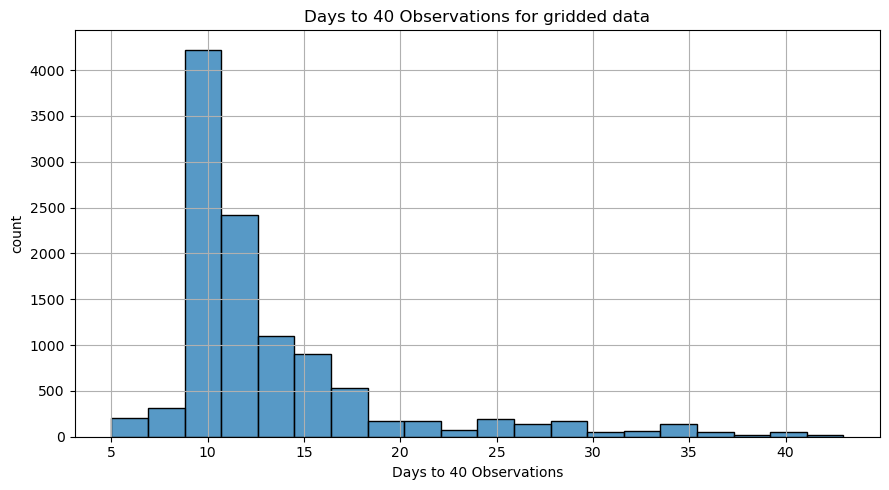

In [5]:
def days_to_n_obs(sub_df, n=BASELINE_MIN_OBS):
    t = sub_df["datetime_local"].sort_values()
    if len(t) < n:
        return np.nan
    return (t.iloc[n - 1] - t.iloc[0]).days + 1

obs_to_40_count = (no2_df.groupby(["grid_lat", "grid_lon"])
                   .apply(days_to_n_obs).rename("days_to_40_obs").reset_index())
print(obs_to_40_count["days_to_40_obs"].describe())

plt.figure(figsize=(9, 5))
sns.histplot(x="days_to_40_obs", bins=20, data=obs_to_40_count)
plt.title("Days to 40 Observations for gridded data")
plt.xlabel("Days to 40 Observations"); plt.ylabel("count")
plt.grid(True); plt.tight_layout(); plt.show()

# Rolling baseline (per grid cell)

In [6]:
def add_pooled_baseline(d, days=BASELINE_DAYS, min_obs=BASELINE_MIN_OBS, value="no2_mean"):
    """Vectorized version of the per-row loop: same window [t - days, t), same >= min_obs rule, same SD (ddof=1)."""
    d = d.sort_values(["grid_lat", "grid_lon", "datetime_local"]).reset_index(drop=True)
    roll = (d.groupby(["grid_lat", "grid_lon"], sort=False)[[value, "datetime_local"]]
            .rolling(f"{days}D", on="datetime_local", closed="left"))
    cnt, mu, sd = roll.count(), roll.mean(), roll.std()
    idx = cnt.index.get_level_values(-1)
    n = pd.Series(cnt[value].to_numpy(), index=idx).reindex(d.index)
    ok = n >= min_obs
    d["rolling_mean"] = pd.Series(mu[value].to_numpy(), index=idx).reindex(d.index).where(ok)
    d["rolling_std"] = pd.Series(sd[value].to_numpy(), index=idx).reindex(d.index).where(ok)
    return d

no2_df = add_pooled_baseline(no2_df)

total = len(no2_df); valid = int(no2_df["rolling_mean"].notna().sum())
print(f"Total rows: {total:,}")
print(f"Rows with a valid rolling mean: {valid:,}  ({100 * valid / total:.2f}%)")

Total rows: 7,506,097
Rows with a valid rolling mean: 6,594,329  (87.85%)


# Detect pulses

Flags NO2 >= rolling_mean + 3*rolling_std

a pulse **starts** at the first hour of a flagged run lasting 2+
consecutive hours. A missing/cloudy hour breaks a run.

In [7]:
def detect_pulses(d, sd=PULSE_SD, min_run=MIN_RUN_HOURS):
    d = d.sort_values(["grid_lat", "grid_lon", "datetime_local"]).reset_index(drop=True)
    d["pulse_threshold"] = d["rolling_mean"] + sd * d["rolling_std"]
    d["above_3sd"] = (d["no2_mean"] >= d["pulse_threshold"]).fillna(False).astype(bool)

    keys = [d["grid_lat"], d["grid_lon"]]
    d["time_diff_hours"] = d.groupby(keys)["datetime_local"].diff().dt.total_seconds() / 3600

    # new run whenever above/below flips OR there's a real time gap
    flipped = d["above_3sd"] != d.groupby(keys)["above_3sd"].shift(1, fill_value=False)
    d["run_id"] = (flipped | (d["time_diff_hours"] != 1)).groupby(keys).cumsum()
    d["run_len"] = d.groupby(keys + [d["run_id"]])["above_3sd"].transform("size")

    # first row of an above-threshold run lasting >= min_run hours
    # (dtype-safe -- replaces the old ~prev_above, which flagged every hour of a run under pandas 3)
    first_in_run = d["run_id"] != d.groupby(keys)["run_id"].shift(1)
    d["pulse_start"] = d["above_3sd"] & first_in_run & (d["run_len"] >= min_run)
    return d

df = detect_pulses(no2_df)
pulses_2hour = df.copy()
df_pulse_2hour_true = df[df["pulse_start"]]
print(f"Total pulse events detected: {len(df_pulse_2hour_true):,}")
print(df_pulse_2hour_true["local_hour"].value_counts().sort_index())

Total pulse events detected: 17,525
local_hour
6       28
7     5782
8     4724
9     2371
10    1392
11     905
12     691
13     409
14     363
15     337
16     276
17     245
18       2
Name: count, dtype: int64


In [8]:
keys = [df["grid_lat"], df["grid_lon"]]
prev = df.groupby(keys)["pulse_start"].shift(1, fill_value=False)
n_bad = int((df["pulse_start"] & prev & (df["time_diff_hours"] == 1)).sum())
assert n_bad == 0, f"{n_bad} pulse starts directly follow another -- detection is broken"
print("OK: every pulse start is the first hour of its run")

OK: every pulse start is the first hour of its run


In [9]:
pulses_2hour.to_parquet(OUTPUT_FILE, engine="pyarrow")
print("Saved to:", OUTPUT_FILE)

Saved to: /global/scratch/users/rubypercival/TEMPO/parquet_V04/GCF_no2_pulses_mar-july_3SD_2hourpulse_all_hours_MCD12Q1mask_24_FIXED.parquet


# comparing early-hour cutoffs

Reruns baseline + detection pretending observations before each local-hour cutoff
don't exist, on a random subset of grid cells.

In [10]:
N_SAMPLE_CELLS = 300
all_cells = no2_df[["grid_lat", "grid_lon"]].drop_duplicates()
sample_cells = all_cells.sample(n=min(N_SAMPLE_CELLS, len(all_cells)), random_state=0)
no2_sample_base = no2_df.merge(sample_cells, on=["grid_lat", "grid_lon"], how="inner")
no2_sample_base = no2_sample_base.drop(columns=["rolling_mean", "rolling_std"], errors="ignore")
print(f"Sampled {len(sample_cells)} grid cells, {len(no2_sample_base):,} rows")

def run_baseline_and_pulses(df_in, hour_cutoff):
    d = df_in if hour_cutoff is None else df_in[df_in["local_hour"] >= hour_cutoff]
    if d.empty:
        return {"hour_cutoff": hour_cutoff, "total_rows": 0, "pct_with_baseline": 0, "n_pulses": 0, "pulses_per_1000_rows": 0}
    d = detect_pulses(add_pooled_baseline(d.copy()))
    n = len(d); n_p = int(d["pulse_start"].sum())
    return {"hour_cutoff": hour_cutoff, "total_rows": n,
            "pct_with_baseline": 100 * d["rolling_mean"].notna().mean(),
            "n_pulses": n_p, "pulses_per_1000_rows": 1000 * n_p / n}

experiment_df = pd.DataFrame([run_baseline_and_pulses(no2_sample_base, c)
                              for c in tqdm([5, 6, 7, 8, 9, 10, None], desc="Testing cutoffs")])
experiment_df["label"] = experiment_df["hour_cutoff"].apply(lambda h: "all hours" if pd.isna(h) else f"{int(h)}am cutoff")
experiment_df

Sampled 300 grid cells, 202,447 rows


Testing cutoffs: 100%|██████████| 7/7 [00:01<00:00,  4.65it/s]


,hour_cutoff,total_rows,pct_with_baseline,n_pulses,pulses_per_1000_rows,label
0,5.0,202447,87.321126,488,2.410507,5am cutoff
1,6.0,202447,87.321126,488,2.410507,6am cutoff
2,7.0,202400,87.318182,488,2.411067,7am cutoff
3,8.0,192717,85.774996,426,2.210495,8am cutoff
4,9.0,174835,80.758429,339,1.938971,9am cutoff
5,10.0,153143,71.161594,224,1.462685,10am cutoff
6,NaN,202447,87.321126,488,2.410507,all hours


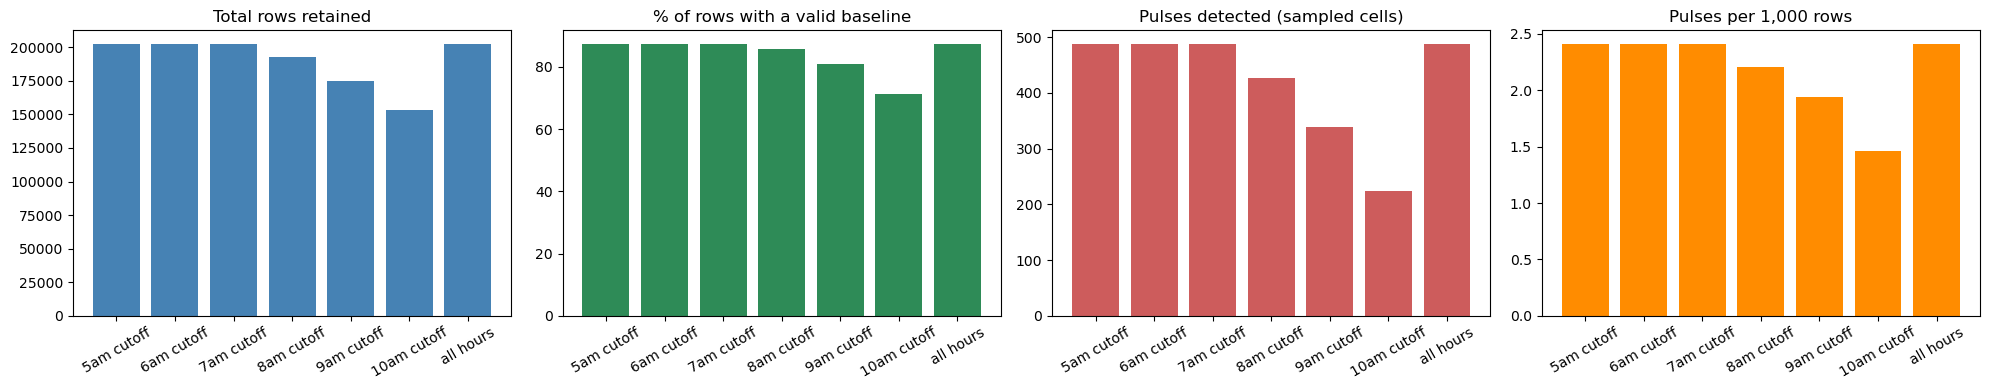

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col, title, color in [(axes[0], "total_rows", "Total rows retained", "steelblue"),
                              (axes[1], "pct_with_baseline", "% of rows with a valid baseline", "seagreen"),
                              (axes[2], "n_pulses", "Pulses detected (sampled cells)", "indianred"),
                              (axes[3], "pulses_per_1000_rows", "Pulses per 1,000 rows", "darkorange")]:
    ax.bar(experiment_df["label"], experiment_df[col], color=color)
    ax.set_title(title); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

In [15]:
df["datetime_local"].dt.hour.value_counts().sort_index().loc[16:20]


datetime_local
16    565123
17    514441
18    329009
19      6964
Name: count, dtype: int64